<a href="https://colab.research.google.com/github/williamli218/mais202-team-2-fraud-bursts/blob/main/notebooks/workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1.1 Setup

Run the code below in order to downlaod your repo onto Colab (using your GitHub token). It will then update it with git pull, load your Kaggle keys, install the needed packages, and make src/ and config.py importable. Run it once at the start of every session.

In [1]:
LOG = False
REPO_URL = "https://github.com/williamli218/mais202-team-2-fraud-bursts"

import os, subprocess, sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if "<your-team>" in REPO_URL:
        raise ValueError("Edit REPO_URL at the top of this cell to your team's repository first.")
    from google.colab import userdata

    def _secret(name):
        try:
            return userdata.get(name)
        except Exception as e:
            raise RuntimeError(
                f"Colab Secret {name} is missing or not shared with this notebook. "
                "Open the key icon in the left sidebar, add it, and switch on Notebook access."
            ) from e

    token = _secret("GITHUB_TOKEN")
    for name in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
        os.environ[name] = _secret(name)

    repo = REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if not os.path.isdir(repo):
        auth_url = REPO_URL.replace("https://", f"https://{token}@")
        subprocess.run(["git", "clone", "--quiet", auth_url], check=True)
    os.chdir(repo)
    subprocess.run(["git", "pull", "--quiet"], check=False)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    # Not in Colab: assume this notebook is open from inside the repository.
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")

sys.path.insert(0, os.getcwd())
import config
print("repository:", os.getcwd(), "| template version:", config.TEMPLATE_VERSION)
print("TRACK in config.py:", config.TRACK, "" if config.TRACK else "<- one teammate sets this and pushes config.py")

repository: /content/mais202-team-2-fraud-bursts | template version: 2026-11-06
TRACK in config.py: 2 


The following code tells git who you are (name and email) so your commits are labelled "William Li" on GitHub. The noreply email keeps your real one private. Run it once per session, before committing

In [2]:
!git config user.name "William Li"
!git config user.email "williamli218@users.noreply.github.com"

## 1.2 Download and load data

In [3]:
from src import data

pool, test = data.load_track02()

Using Colab cache for faster access to the 'fraud-detection' dataset.
Using Colab cache for faster access to the 'fraud-detection' dataset.


## 1.3 Quick look

In [ ]:
data.quick_look(pool, "is_fraud", "train pool")
data.quick_look(test, "is_fraud", "test")
attacked = pool.groupby("cc_num", observed=True)["is_fraud"].max()
print(f"cards in pool: {len(attacked):,}, attacked (at least one fraud): {int(attacked.sum()):,}")

train pool: 1,296,675 rows x 19 columns, 335 MB in memory
columns: trans_date_trans_time, cc_num, merchant, category, amt, gender, city, state, zip, lat, long, city_pop, job, dob, trans_num, unix_time, merch_lat, merch_long, is_fraud
is_fraud == 1: 7,506 of 1,296,675 (0.579%)
test: 555,719 rows x 19 columns, 144 MB in memory
columns: trans_date_trans_time, cc_num, merchant, category, amt, gender, city, state, zip, lat, long, city_pop, job, dob, trans_num, unix_time, merch_lat, merch_long, is_fraud
is_fraud == 1: 2,145 of 555,719 (0.386%)
cards in pool: 983, attacked (at least one fraud): 762


## 1.4 Fixed test split

In [ ]:
print("train pool:", pool["trans_date_trans_time"].min(), "->", pool["trans_date_trans_time"].max())
print("test:      ", test["trans_date_trans_time"].min(), "->", test["trans_date_trans_time"].max())

train pool: 2019-01-01 00:00:18 -> 2020-06-21 12:13:37
test:       2020-06-21 12:14:25 -> 2020-12-31 23:59:34


## 1.5 Validation split
In order to choose for a validation cut date, a month-by-month view of transactions and fraud is displayed in the following table. `src/split.py`

In [ ]:
import pandas as pd
t = pd.to_datetime(pool["trans_date_trans_time"])
month = t.dt.to_period("M")

fraud = pool[pool["is_fraud"] == 1]
first_fraud = fraud.assign(t=t[fraud.index]).groupby("cc_num", observed=True)["t"].min()

monthly = pd.DataFrame({
    "rows": pool.groupby(month).size(),
    "fraud_tx": pool.groupby(month)["is_fraud"].sum(),
    "attacks_starting": first_fraud.dt.to_period("M").value_counts(),
}).fillna(0).astype(int)
monthly["fraud_rate_%"] = (100 * monthly["fraud_tx"] / monthly["rows"]).round(3)
monthly

fr = fraud.assign(t=t[fraud.index]).groupby("cc_num", observed=True)["t"].agg(["min", "max"])

rows = []
for cut in pd.date_range("2019-09-01", "2020-04-01", freq="MS"):
    rows.append({
        "cut": cut.date(),
        "train_months": round((cut - t.min()).days / 30.4, 1),
        "valid_months": round((t.max() - cut).days / 30.4, 1),
        "attacks_in_valid": int((fr["min"] >= cut).sum()),
        "straddling_cut": int(((fr["min"] < cut) & (fr["max"] >= cut)).sum()),
    })
pd.DataFrame(rows)

,cut,train_months,valid_months,attacks_in_valid,straddling_cut
0,2019-09-01,8.0,9.7,423,3
1,2019-10-01,8.9,8.7,382,0
2,2019-11-01,10.0,7.7,332,3
3,2019-12-01,11.0,6.7,294,3
4,2020-01-01,12.0,5.7,235,2
5,2020-02-01,13.0,4.6,197,3
6,2020-03-01,13.9,3.7,165,1
7,2020-04-01,15.0,2.7,121,3


Choice of validation cut date: January 1st, 2020.

Done with helper functions from src/split.py

Reasons:
1. It gives a full year of training (all of 2019, every season, including holidays)
2. It gives a validation window close to the test set's length  (5.7 vs 6.3 months)
3. It gives plenty of attacks in validation (235, enough for a stable median)
4. Almost no attacks are split by the cut (only 2)

In [4]:
from src import split

try:
    train, valid = split.make_validation_split(pool)
except NotImplementedError as e:
    train = valid = None
    print(e)
else:
    split.check_split(train, valid, *split.default_columns())
    print(f"train: {len(train):,} rows, valid: {len(valid):,} rows; both checks passed")

train: 924,850 rows, valid: 371,825 rows; both checks passed


In [ ]:
!python -m pytest -q tests/test_leakage.py

....                                                                     [100%]
4 passed in 0.61s


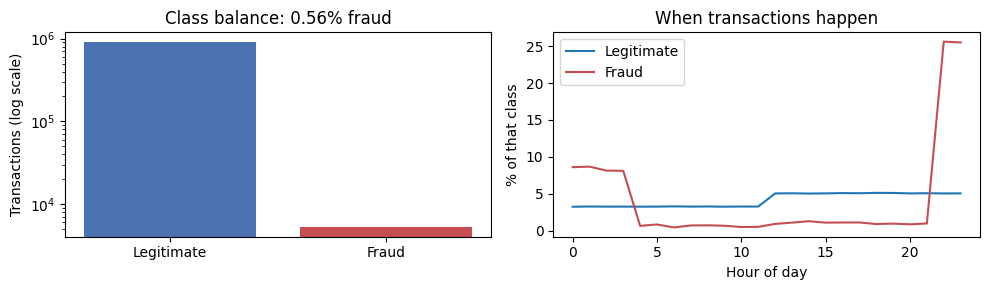

In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))

counts = train["is_fraud"].value_counts().sort_index()
ax1.bar(["Legitimate", "Fraud"], counts.values, color=["#4C72B0", "#C44E52"])
ax1.set_yscale("log")
ax1.set_ylabel("Transactions (log scale)")
ax1.set_title(f"Class balance: {100 * train['is_fraud'].mean():.2f}% fraud")

hour = pd.to_datetime(train["trans_date_trans_time"]).dt.hour
by_hour = pd.crosstab(hour, train["is_fraud"], normalize="columns") * 100
ax2.plot(by_hour.index, by_hour[0], label="Legitimate")
ax2.plot(by_hour.index, by_hour[1], label="Fraud", color="#C44E52")
ax2.set_xlabel("Hour of day")
ax2.set_ylabel("% of that class")
ax2.set_title("When transactions happen")
ax2.legend()

plt.tight_layout()
plt.show()

## 1.6 Features
Helper function from `src/features.py`


In [ ]:
from src import features

features.build_features(pool.head(10))

,log_seconds_since_prev,transaction_count_past_24h,log_spend_past_24h,amount_vs_recent_mean,is_night,cat_entertainment,cat_food_dining,cat_gas_transport,cat_grocery_net,cat_grocery_pos,...,cat_personal_care,cat_shopping_net,cat_shopping_pos,cat_travel,amt_band_0,amt_band_1,amt_band_2,amt_band_3,amt_band_4,amt_band_5
0,14.767941,1.0,1.786747,1.0,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
1,14.767941,1.0,4.684258,1.0,1,0,0,0,0,1,...,0,0,0,0,0,1,0,0,0,0
2,14.767941,1.0,5.398660,1.0,1,1,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
3,14.767941,1.0,3.828641,1.0,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,0
4,14.767941,1.0,3.760269,1.0,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
5,14.767941,1.0,4.560487,1.0,1,0,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0
6,14.767941,1.0,3.818591,1.0,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
7,14.767941,1.0,4.285654,1.0,1,0,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0
8,14.767941,1.0,1.662030,1.0,1,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
9,14.767941,1.0,5.295263,1.0,1,0,0,0,0,1,...,0,0,0,0,0,1,0,0,0,0


## 1.7 The trivial baseline
The baseline calls every row legitimate: every score is 0. It's here to be scored with your metric and with accuracy, side by side, before you train anything. On this track it will look very accurate and catch nothing. That gap is the point of the evaluation metric section of your proposal. Helper function from src/metrics.py

In [ ]:
from src.models import always_legitimate
from sklearn.metrics import accuracy_score

baseline_scores = always_legitimate(len(pool))
print("baseline scores:", baseline_scores[:5], "... (all zeros)")
labelled = pool["is_fraud"] != -1
print("accuracy on the train pool if we predict 'legitimate' everywhere:",
      round(accuracy_score(pool["is_fraud"][labelled], (baseline_scores[labelled] >= 0.5).astype(int)), 4))

from src import metrics
y_valid = valid["is_fraud"].to_numpy()
s_valid = always_legitimate(len(valid))
print("headline metric:", metrics.median_frauds_before_hold(y_valid, s_valid, valid["cc_num"].to_numpy(), max_legit_hold_rate=0.01))
print("accuracy:       ", accuracy_score(y_valid, (s_valid >= 0.5).astype(int)))

baseline scores: [0. 0. 0. 0. 0.] ... (all zeros)
accuracy on the train pool if we predict 'legitimate' everywhere: 0.9942
headline metric: 9.0
accuracy:        0.993851946480199


## 1.8 Sequences
`make_sequences` turns the table into one fixed-length window per
transaction: the card's last `n` transactions ending at it, oldest first,
zero-padded while the card has fewer than `n`. `X` is what a sequence model
reads; `y` is the label of the last transaction in each window; `meta` keeps
the card, the time and how many rows in the window are real.

In [ ]:
X, y, meta = data.make_sequences(pool, n=10, feature_cols=["amt"])
print("X:", X.shape, X.dtype, "| y:", y.shape, "| meta columns:", list(meta.columns))
print("memory for X: %.0f MB" % (X.nbytes / 1e6))
i = int(meta.index[meta["n_valid"] == 10][0])
print("one window (amount only), oldest first:", X[i, :, 0].round(2))

X: (1296675, 10, 1) float32 | y: (1296675,) | meta columns: ['cc_num', 'unix_time', 'is_fraud', 'n_valid']
memory for X: 52 MB
one window (amount only), oldest first: [ 46.97  64.48  51.39  68.04  73.57  40.31 217.54   4.98  34.13  17.22]


In [ ]:
!python -m pytest -q tests/test_metrics.py tests/test_leakage.py

ssssss......ssssssssssssssssssssssssssssssssssssssss....                 [100%]
10 passed, 46 skipped in 0.70s


## 2.1 Simple baseline model: logistic regression
Train model and evaluate score `src/models.py`

In [ ]:
import numpy as np, pandas as pd
from src import features, models, metrics

feats = features.build_features(pool)
X_train, X_valid = feats.loc[train.index], feats.loc[valid.index]
model = models.train_logistic_regression(X_train, train["is_fraud"])
s_valid = model.predict_proba(X_valid)[:, 1]
print("headline metric:", metrics.median_frauds_before_hold(
    valid["is_fraud"], s_valid, valid["cc_num"], max_legit_hold_rate=0.01))

headline metric: 9.0


Added and tested smoothing window of different sizes

In [ ]:
v = pd.DataFrame({"card": valid["cc_num"].to_numpy(), "s": s_valid})
for k in [2, 3, 5]:
    s_k = v.groupby("card", observed=True)["s"].transform(lambda x: x.rolling(k, min_periods=1).mean()).to_numpy()
    print(k, metrics.median_frauds_before_hold(valid["is_fraud"], s_k, valid["cc_num"], max_legit_hold_rate=0.01))

2 5.0
3 3.0
5 4.0


Save the model in `models/`

In [ ]:
import json
scaler = model.named_steps["standardscaler"]
lr = model.named_steps["logisticregression"]

params = {
    "features": list(X_train.columns),
    "mean": scaler.mean_.tolist(),
    "scale": scaler.scale_.tolist(),
    "coef": lr.coef_[0].tolist(),
    "intercept": float(lr.intercept_[0]),
    "smooth_k": 3,
}
with open("models/logistic_regression.json", "w") as f:
    json.dump(params, f, indent=2)

Log experiments in `experiments/log.csv`

In [ ]:
import csv, datetime

def log_run(model, settings, metric, value, notes=""):
    with open("experiments/log.csv", "a", newline="") as f:
        csv.writer(f).writerow([datetime.date.today().isoformat(), "William Li",
                                model, settings, "valid", metric, value, notes])

if LOG:
    log_run("all_legitimate", "score 0 everywhere", "median_frauds_before_hold", 9.0, "D1.5 baseline")
    log_run("all_legitimate", "score 0 everywhere", "accuracy", 0.9939)
    log_run("logistic_regression", "improved features, class_weight=balanced", "median_frauds_before_hold", 9.0)
    log_run("logistic_regression", "+ amount bands", "median_frauds_before_hold", 9.0, "AUC 0.989")
    for k, val in [(2, 5.0), (3, 3.0), (5, 4.0)]:
        log_run("logistic_regression", f"+ amount bands + smoothing k={k}", "median_frauds_before_hold", val)

## 2.2 Main model: LSTM
`src/models.py`

In [ ]:
from src import models

d = models.prepare_lstm_data(pool, train, valid, n=10)
lstm, history = models.train_lstm(d["X_tr"], d["y_tr"], d["X_va"], d["y_va"])

Epoch 1/15, train loss 0.5197, valid loss 0.2818
Epoch 2/15, train loss 0.2440, valid loss 0.1972
Epoch 3/15, train loss 0.1679, valid loss 0.1537
Epoch 4/15, train loss 0.1265, valid loss 0.1261
Epoch 5/15, train loss 0.0999, valid loss 0.1062
Epoch 6/15, train loss 0.0828, valid loss 0.0953
Epoch 7/15, train loss 0.0688, valid loss 0.1041
Epoch 8/15, train loss 0.0585, valid loss 0.0897
Epoch 9/15, train loss 0.0508, valid loss 0.0893
Epoch 10/15, train loss 0.0454, valid loss 0.0768
Epoch 11/15, train loss 0.0400, valid loss 0.0744
Epoch 12/15, train loss 0.0355, valid loss 0.0772
Epoch 13/15, train loss 0.0332, valid loss 0.0970
Epoch 14/15, train loss 0.0292, valid loss 0.1046
Early stopping: no improvement for 3 epochs.


In [ ]:
s_lstm = models.lstm_scores(lstm, d["X_va"])
cards_va = d["meta_va"]["cc_num"].to_numpy()
y_va = d["meta_va"]["is_fraud"].to_numpy()

med = metrics.median_frauds_before_hold(y_va, s_lstm, cards_va, max_legit_hold_rate=0.01)
med_smooth = metrics.median_frauds_before_hold(y_va, models.smooth_scores(s_lstm, cards_va), cards_va, max_legit_hold_rate=0.01)

print("LSTM:              ", med)
print("LSTM + smoothing 3:", med_smooth)

LSTM:               2.0
LSTM + smoothing 3: 3.0


Save model in `models/` and data in `experiments/log.csv`

In [ ]:
torch.save(lstm.state_dict(), "models/lstm_n10.pt")
with open("models/lstm_n10.json", "w") as f:
    json.dump({"features": features.LSTM_COLS, "n": 10, "hidden_dim": 32,
               "mean": d["mean"].tolist(), "std": d["std"].tolist(), "history": history}, f, indent=2)

In [ ]:
if LOG:
    log_run("lstm", "n=10, hidden=32, lr=1e-3, batch 2048, pos_weight, early stop", "median_frauds_before_hold", med, "T4")
    log_run("lstm", "same + smoothing k=3", "median_frauds_before_hold", med_smooth)

## 2.3 Required experiments
Models comparison with median

In [ ]:
from src import metrics
import numpy as np

def M(y, s, cards):
    return metrics.median_frauds_before_hold(np.asarray(y), s, np.asarray(cards), max_legit_hold_rate=0.01)

p = models.load_logistic_regression()
s_lr_tr = models.logistic_regression_scores(p, feats.loc[train.index])
s_lr_va = models.logistic_regression_scores(p, feats.loc[valid.index])

s_lstm_tr = models.lstm_scores(lstm, d["X_tr"])

results = {
    "LR": (M(train["is_fraud"], s_lr_tr, train["cc_num"]),
           M(valid["is_fraud"], s_lr_va, valid["cc_num"])),
    "LR + smoothing (k=3)": (M(train["is_fraud"], models.smooth_scores(s_lr_tr, train["cc_num"]), train["cc_num"]),
                             M(valid["is_fraud"], models.smooth_scores(s_lr_va, valid["cc_num"]), valid["cc_num"])),
    "LSTM (n=10)": (M(d["meta_tr"]["is_fraud"], s_lstm_tr, d["meta_tr"]["cc_num"]),
                M(d["meta_va"]["is_fraud"], s_lstm, d["meta_va"]["cc_num"])),
}
for name, (tr, va) in results.items():
    print(f"{name:22s} train {tr:4.1f} | valid {va:4.1f}")

LR                     train 10.0 | valid  9.0
LR + smoothing (k=3)   train  5.0 | valid  3.0
LSTM (n=10)            train  2.0 | valid  2.0


Figures for comparison

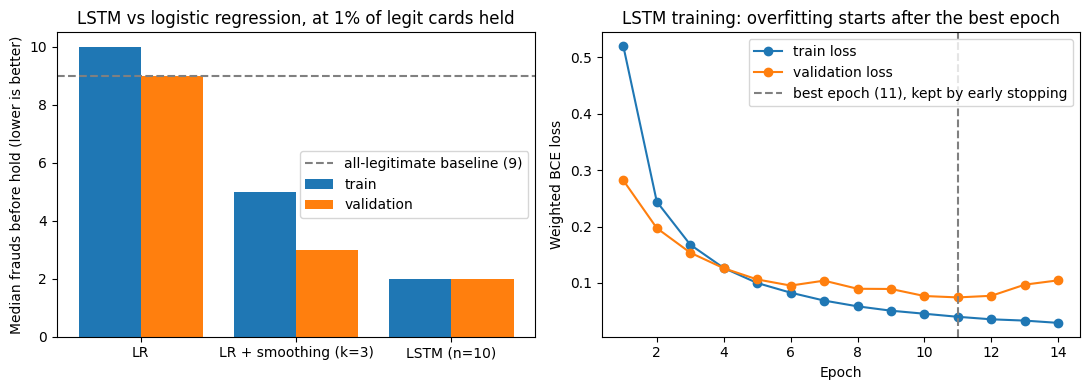

In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

names = list(results.keys())
tr = [results[n][0] for n in names]
va = [results[n][1] for n in names]
x = np.arange(len(names))
ax1.bar(x - 0.2, tr, width=0.4, label="train")
ax1.bar(x + 0.2, va, width=0.4, label="validation")
ax1.axhline(9, color="grey", linestyle="--", label="all-legitimate baseline (9)")
ax1.set_xticks(x)
ax1.set_xticklabels(names)
ax1.set_ylabel("Median frauds before hold (lower is better)")
ax1.set_title("LSTM vs logistic regression, at 1% of legit cards held")
ax1.legend()

ep = [h["epoch"] for h in history]
ax2.plot(ep, [h["train_loss"] for h in history], marker="o", label="train loss")
ax2.plot(ep, [h["valid_loss"] for h in history], marker="o", label="validation loss")
best = min(history, key=lambda h: h["valid_loss"])["epoch"]
ax2.axvline(best, color="grey", linestyle="--", label=f"best epoch ({best}), kept by early stopping")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Weighted BCE loss")
ax2.set_title("LSTM training: overfitting starts after the best epoch")
ax2.legend()

plt.tight_layout()
plt.show()

## 2.4 Results table
Precision and recall calculations

In [ ]:
import pandas as pd

def operating_point(y, s, cards, max_rate=0.01):
    """Card-level precision and recall at the threshold the headline metric uses."""
    df = pd.DataFrame({"card": np.asarray(cards), "y": np.asarray(y).astype(int), "s": np.asarray(s, dtype=float)})
    per_card = df.groupby("card", sort=False).agg(attacked=("y", "max"), max_score=("s", "max"))
    legit = np.sort(per_card.loc[per_card["attacked"] == 0, "max_score"].to_numpy())
    cand = np.append(np.unique(df["s"]), np.inf)
    rate = (len(legit) - np.searchsorted(legit, cand, side="left")) / len(legit)
    t = cand[np.argmax(rate <= max_rate)]

    df["pos"] = df.groupby("card", sort=False).cumcount()
    first_hold = df[df["s"] >= t].groupby("card", sort=False)["pos"].min()
    last_fraud = df[df["y"] == 1].groupby("card", sort=False)["pos"].max()

    held = per_card.index.isin(first_hold.index)
    attacked = per_card["attacked"].to_numpy() == 1
    caught = last_fraud.index[first_hold.reindex(last_fraud.index) <= last_fraud]

    precision = (held & attacked).sum() / held.sum() if held.sum() else float("nan")
    recall = len(caught) / attacked.sum()
    return t, precision, recall

rows = {
    "All-legitimate": (valid["is_fraud"], np.zeros(len(valid)), valid["cc_num"]),
    "LR": (valid["is_fraud"], s_lr_va, valid["cc_num"]),
    "LR + smoothing (k=3)": (valid["is_fraud"], models.smooth_scores(s_lr_va, valid["cc_num"]), valid["cc_num"]),
    "LSTM (n=10)": (d["meta_va"]["is_fraud"], s_lstm, d["meta_va"]["cc_num"]),
}
for name, (y_, s_, c_) in rows.items():
    t, p, r = operating_point(y_, s_, c_)
    print(f"{name:22s} threshold {t:.4f} | precision {p:.2f} | recall {r:.2f}")

All-legitimate         threshold inf | precision nan | recall 0.00
LR                     threshold 0.9998 | precision 0.50 | recall 0.02
LR + smoothing (k=3)   threshold 0.9772 | precision 0.97 | recall 0.92
LSTM (n=10)            threshold 0.9992 | precision 0.97 | recall 0.96


In [ ]:
for name, (y_, s_, c_) in rows.items():
    t, p, r = operating_point(y_, s_, c_)
    print(f"{name:22s} threshold {t:.4f} | precision {p:.2f} | recall {r:.2f}")
    if LOG:
        log_run(name, "validation, 1% legit-card budget", "precision_cards", round(float(p), 3) if p == p else "nan")
        log_run(name, "validation, 1% legit-card budget", "recall_cards", round(float(r), 3))

## 2.5 Error analysis
Missed frauds and false holds

In [ ]:
import config

meta_va = d["meta_va"]
t_lstm, _, _ = operating_point(meta_va["is_fraud"], s_lstm, meta_va["cc_num"])

ev = meta_va[["cc_num", "is_fraud", "n_valid"]].copy()
ev["score"] = s_lstm
ev = ev.join(pool[["trans_date_trans_time", "amt", "category"]])
ev["gap_min"] = (np.expm1(feats.loc[ev.index, "log_seconds_since_prev"]) / 60).round(1)

g = ev.groupby("cc_num", observed=True, sort=False)
ev["flag"] = ev["score"] >= t_lstm
ev["held"] = g["flag"].cummax()
ev["fraud_no"] = g["is_fraud"].cumsum()
ev["card_attacked"] = g["is_fraud"].transform("max")

missed = ev[(ev["is_fraud"] == 1) & (~ev["held"])]
false_holds = ev[(ev["card_attacked"] == 0) & ev["flag"]].groupby("cc_num", observed=True).head(1)

print("threshold:", round(t_lstm, 4))
print("missed frauds:", len(missed), "| honest cards held:", len(false_holds))
print("\nwhich fraud in the burst got through (1 = first fraud on the card):")
print(missed["fraud_no"].value_counts().sort_index().head(10))

cols = ["trans_date_trans_time", "amt", "category", "gap_min", "n_valid", "fraud_no", "score"]

print("=== 5 random missed frauds ===")
print(missed.sample(5, random_state=config.SEED)[cols].to_string())

print("\n=== 5 random false holds (honest cards) ===")
print(false_holds.sample(5, random_state=config.SEED)[cols[:-2] + ["score"]].to_string())

threshold: 0.9992
missed frauds: 565 | honest cards held: 6

which fraud in the burst got through (1 = first fraud on the card):
fraud_no
1    232
2    176
3     86
4     42
5     16
6      6
7      5
8      2
Name: count, dtype: int64
=== 5 random missed frauds ===
        trans_date_trans_time         amt        category     gap_min  n_valid  fraud_no     score
979286    2020-02-02 01:41:23  286.359985     grocery_pos   10.100000       10         3  0.993589
1278638   2020-06-14 23:33:40   24.750000  health_fitness   15.600000       10         4  0.998168
1062873   2020-03-17 01:01:04   19.540001   gas_transport  926.799988       10         1  0.925736
1206799   2020-05-19 09:25:17   11.020000   gas_transport  912.400024       10         1  0.758797
1168468   2020-05-03 03:03:19  514.169983   entertainment  342.299988       10         1  0.983837

=== 5 random false holds (honest cards) ===
        trans_date_trans_time          amt      category      gap_min  n_valid     score
12387

## 2.6 Predict
Prepare `predict()` method in `src/predict.py` for test data and new incoming data

In [ ]:
!python -m pytest -q tests/test_predict.py

...                                                                      [100%]
3 passed in 4.36s


## 3.1 Threshold
Choose threshold based on minimal cost and `hold_rate <= 0.01`

In [ ]:
from src import decision

s_va = s_lstm
amt_va = pool.loc[meta_va.index, "amt"].to_numpy()
curve = decision.cost_curve(meta_va["is_fraud"], s_va, amt_va, meta_va["cc_num"])
best = decision.choose_thresholds(meta_va["is_fraud"], s_va, amt_va, meta_va["cc_num"])
print(best)

print(curve[curve["threshold"].isin([t_lstm, best["hold"]])].to_string())

{'hold': 0.9991763234138489, 'hold_hours': 72}
        threshold  legit_cards_held  legit_hold_rate  frauds_missed  missed_fraud_cost     total_cost
365184   0.999175                 6         0.008646            565      233394.480176  233484.480176
365185   0.999176                 5         0.007205            565      233394.480176  233469.480176


We can see that a better threshold has been found by minimizing cost while maintaining the `hold_rate <= 0.01`.
Now save in `models/`

In [ ]:
import json
with open("models/thresholds.json", "w") as f:
    json.dump({"hold": best["hold"], "hold_hours": 72}, f, indent=2)

## 3.2 Holding time

Choose for how long the card gets hold after being identified as a fraud

In [ ]:
import pandas as pd

t = pd.to_datetime(train["trans_date_trans_time"])
fraud = train[train["is_fraud"] == 1]
span = fraud.assign(t=t[fraud.index]).groupby("cc_num", observed=True)["t"].agg(["min", "max"])
hours = (span["max"] - span["min"]).dt.total_seconds() / 3600

print("attacks:", len(hours))
print("attack length in hours:")
print(hours.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))

attacks: 527
attack length in hours:
count    527.0
mean      40.3
std        9.1
min        0.1
50%       45.1
90%       47.2
95%       47.4
99%       47.7
max       47.9
dtype: float64


In [ ]:
times_va = pool.loc[meta_va.index, "trans_date_trans_time"]

for hours in [24, 48, 72, 96]:
    print(f"{hours:3d}h", decision.evaluate(s_va, meta_va["cc_num"], meta_va["is_fraud"],
                                            amt_va, times_va, best["hold"], hours))

 24h {'median frauds before hold': 2.0, 'honest cards held': 5, 'honest hold rate': 0.0072, 'fraud charges through': 617, 'total cost $': 246197}
 48h {'median frauds before hold': 2.0, 'honest cards held': 5, 'honest hold rate': 0.0072, 'fraud charges through': 568, 'total cost $': 234459}
 72h {'median frauds before hold': 2.0, 'honest cards held': 5, 'honest hold rate': 0.0072, 'fraud charges through': 568, 'total cost $': 234459}
 96h {'median frauds before hold': 2.0, 'honest cards held': 5, 'honest hold rate': 0.0072, 'fraud charges through': 568, 'total cost $': 234459}


Chose 72h since 48h is a really tight bound

In [ ]:
for name, hours in [("72h + re-hold", 72), ("hold forever", 10**7)]:
    print(f"{name:14s}", decision.evaluate(s_va, meta_va["cc_num"], meta_va["is_fraud"],
                                           amt_va, times_va, best["hold"], hours))

72h + re-hold  {'median frauds before hold': 2.0, 'honest cards held': 5, 'honest hold rate': 0.0072, 'fraud charges through': 568, 'total cost $': 234459}
hold forever   {'median frauds before hold': 3.0, 'honest cards held': 5, 'honest hold rate': 0.0072, 'fraud charges through': 762, 'total cost $': 270355}


Save in `models/`

In [ ]:
import json
with open("models/thresholds.json", "w") as f:
    json.dump({"hold": best["hold"], "hold_hours": 72}, f, indent=2)

## 3.3 Test data
Score the testing dataset

In [ ]:
import gc
import numpy as np, pandas as pd
from src import models, decision
from src import predict

m = predict.load_model()

for name in ["X", "X_va"]:
    if name in globals():
        del globals()[name]
gc.collect()

full = pd.concat([pool.assign(is_test=False), test.assign(is_test=True)], ignore_index=True)
full["cc_num"] = full["cc_num"].astype("int64")

X_f, _, meta_f = models.make_lstm_windows(full, n=m["n"])
X_f = models.scale_windows(X_f, meta_f, m["mean"], m["std"])

is_te = full.loc[meta_f.index, "is_test"].to_numpy()
X_te, meta_te = X_f[is_te], meta_f[is_te]
del X_f; gc.collect()

s_te = models.lstm_scores(m["lstm"], X_te)
amt_te = full.loc[meta_te.index, "amt"].to_numpy()
times_te = full.loc[meta_te.index, "trans_date_trans_time"]
times_va = pool.loc[meta_va.index, "trans_date_trans_time"]
print("test windows:", X_te.shape, "| fraud share %.4f" % meta_te["is_fraud"].mean())

D2_T = 0.9991745352745056
FOREVER = 24 * 365 * 10
rules = [("Doing nothing", np.inf, 72),
         ("LSTM, D2 threshold (hold forever)", D2_T, FOREVER),
         ("Decision layer (D3: cost threshold + 72h)", best["hold"], 72)]

def comparison(scores, meta_part, amts, times):
    return pd.DataFrame({name: decision.evaluate(scores, meta_part["cc_num"], meta_part["is_fraud"],
                                                 amts, times, t, h)
                         for name, t, h in rules}).T

print("\nTEST")
print(comparison(s_te, meta_te, amt_te, times_te).to_string())
print("\nVALIDATION (for comparison)")
print(comparison(s_va, meta_va, amt_va, times_va).to_string())

test windows: (555719, 10, 17) | fraud share 0.0039

TEST
                                           median frauds before hold  honest cards held  honest hold rate  fraud charges through  total cost $
Doing nothing                                                   10.0                0.0             0.000                 2145.0     1133325.0
LSTM, D2 threshold (hold forever)                                2.0               12.0             0.017                  569.0      221563.0
Decision layer (D3: cost threshold + 72h)                        2.0               12.0             0.017                  577.0      224923.0

VALIDATION (for comparison)
                                           median frauds before hold  honest cards held  honest hold rate  fraud charges through  total cost $
Doing nothing                                                    9.0                0.0            0.0000                 2286.0     1220266.0
LSTM, D2 threshold (hold forever)                      

Save in `models/`

In [ ]:
import csv, datetime

if LOG:
    for name, t, h in [("all_legitimate", np.inf, 72),
                       ("lstm_d2_threshold", D2_T, FOREVER),
                       ("decision_layer_d3", best["hold"], 72)]:
        r = decision.evaluate(s_te, meta_te["cc_num"], meta_te["is_fraud"], amt_te, times_te, t, h)
        for metric in ["median frauds before hold", "honest cards held", "fraud charges through", "total cost $"]:
            with open("experiments/log.csv", "a", newline="") as f:
                csv.writer(f).writerow([datetime.date.today().isoformat(), "William Li", name,
                                        f"threshold {t}, hold {h}h", "test", metric, r[metric], "D3 test, run once"])

## 3.4 Find data for demo
One for each case: allow, hold, and hold on 72h

In [5]:
import pandas as pd
from src import predict

cols = ["trans_date_trans_time", "cc_num", "merchant", "category", "amt", "unix_time"]

def card_rows(card):
    return pool[pool["cc_num"] == card].sort_values("unix_time").reset_index(drop=True)

attacked = valid.loc[valid["is_fraud"] == 1, "cc_num"].unique()
hold_example = None
for card in attacked[:50]:
    rows = card_rows(card)
    in_valid = pd.to_datetime(rows["trans_date_trans_time"]) >= "2020-01-01"
    first = rows.index[(rows["is_fraud"] == 1) & in_valid][0]
    w = rows.iloc[max(0, first + 2 - 11): first + 3]
    if predict.predict(w[cols])["decision"] == "hold":
        hold_example = w
        break

honest = sorted(set(valid["cc_num"]) - set(attacked))
for card in honest[:50]:
    rows = card_rows(card)
    w = rows[pd.to_datetime(rows["trans_date_trans_time"]) >= "2020-01-01"].tail(12)
    if predict.predict(w[cols])["decision"] == "allow":
        allow_example = w
        break

for name, ex in [("HOLD", hold_example), ("ALLOW", allow_example)]:
    print(f"=== {name} example ===")
    print(ex[cols + ["is_fraud"]].tail(4).to_string())
    print(predict.predict(ex[cols]), "\n")

=== HOLD example ===
    trans_date_trans_time          cc_num                                    merchant       category         amt   unix_time  is_fraud
378   2019-12-31 22:17:45  30181367542315  fraud_Romaguera, Cruickshank and Greenholt   shopping_net  940.770020  1356992265         1
379   2020-01-01 03:56:59  30181367542315                       fraud_Vandervort-Funk    grocery_pos  291.239990  1357012619         1
380   2020-01-02 07:05:34  30181367542315             fraud_Ruecker, Beer and Collier   shopping_net   35.830002  1357110334         0
381   2020-01-03 05:51:01  30181367542315                           fraud_Huels-Nolan  gas_transport   55.369999  1357192261         0
{'score': 0.005610142834484577, 'decision': 'hold', 'reasons': ['card on hold since 2020-01-01 03:56 (72h hold)']} 

=== ALLOW example ===
     trans_date_trans_time           cc_num                merchant      category         amt   unix_time  is_fraud
2061   2020-06-19 23:35:22  180011453250192   fra

In [6]:
thr = predict.load_model()["threshold"]
caught_example = None
for card in attacked[:80]:
    rows = card_rows(card)
    t = pd.to_datetime(rows["trans_date_trans_time"])
    fr = rows.index[(rows["is_fraud"] == 1) & (t >= "2020-01-01")]
    if len(fr) == 0 or rows.loc[: fr[0] - 1, "is_fraud"].tail(20).any():
        continue                                   # skip attacks that started before validation
    for end in range(fr[0], fr[0] + 4):            # the first few charges of the attack
        w = rows.iloc[max(0, end - 11): end + 1]
        out = predict.predict(w[cols])
        if out["decision"] == "hold" and out["score"] >= thr:
            caught_example = w
            break
    if caught_example is not None:
        break

print(caught_example[cols + ["is_fraud"]].tail(4).to_string())
print(predict.predict(caught_example[cols]))

    trans_date_trans_time               cc_num                merchant     category         amt   unix_time  is_fraud
369   2020-01-01 14:48:01  4756039869079882102  fraud_Eichmann-Kilback         home   49.450001  1357051681         0
370   2020-01-02 01:26:24  4756039869079882102         fraud_Kiehn Inc  grocery_pos  259.570007  1357089984         1
371   2020-01-02 01:47:46  4756039869079882102     fraud_Auer-Mosciski  grocery_pos  316.640015  1357091266         1
372   2020-01-02 03:22:51  4756039869079882102      fraud_Rau and Sons  grocery_pos  305.709991  1357096971         1
{'score': 0.9994951486587524, 'decision': 'hold', 'reasons': ['$1,010 spent in the last 24 hours (5 charges)', "$306 is over 3x this card's recent average", 'late-night charge (22:00-04:59)', 'high-risk category (grocery_pos)']}


Save sample data in `examples/`

In [ ]:
import os
os.makedirs("examples", exist_ok=True)
caught_example[cols].to_csv("examples/attack_caught.csv", index=False)
hold_example[cols].to_csv("examples/still_on_hold.csv", index=False)
allow_example[cols].to_csv("examples/normal_card.csv", index=False)
!ls examples
!git check-ignore -v examples/*.csv || echo "not ignored, OK to commit"

## 3.5 Demo

In [7]:
import app
app.demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4972951d0f34060a45.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
